In [16]:
import scipy.io as sio
import numpy as np
import matplotlib.pyplot as plt
import os
from PIL import Image
import cv2
import time

# Đọc 3 file .mat cần thiết cho quy trình
labels_data = sio.loadmat('imagelabels.mat', squeeze_me=True)
setid_data = sio.loadmat('setid.mat', squeeze_me=True)

# Đọc file distancematrices102.mat (Dù ta chưa dùng ngay, nhưng đọc để đủ 5 file)
# File này chứa ma trận khoảng cách Chi2, thường dùng cho các phương pháp Matching đặc biệt
try:
    dist_data = sio.loadmat('distancematrices102.mat', squeeze_me=True)
    print("Đã tải thành công distancematrices102.mat")
    print("Các key trong file distance:", dist_data.keys())
except Exception as e:
    print("Lỗi tải distancematrices102.mat:", e)

labels = labels_data['labels']
train_ids = setid_data['trnid']
val_ids = setid_data['valid']
test_ids = setid_data['tstid']

print(f"Tổng số ảnh: {len(labels)}")
print(f"Số lớp: {len(np.unique(labels))}")
print(f"Train: {len(train_ids)}, Val: {len(val_ids)}, Test: {len(test_ids)}")

Đã tải thành công distancematrices102.mat
Các key trong file distance: dict_keys(['__header__', '__version__', '__globals__', 'Dsiftint', 'Dhsv', 'Dsiftbdy', 'Dhog'])
Tổng số ảnh: 8189
Số lớp: 102
Train: 1020, Val: 1020, Test: 6149


In [1]:
import os
import numpy as np
import cv2
from PIL import Image
import matplotlib.pyplot as plt

# Hàm load và cắt ảnh dựa trên file segmentation (mask)
def load_and_crop_image(img_id, target_size=(128, 128)):
    # Đã sửa đường dẫn để trỏ đúng vào thư mục của bạn
    img_path = os.path.join('102flowers (1)', 'jpg', f'image_{img_id:05d}.jpg')
    
    # Bạn kiểm tra lại xem thư mục segmentation của bạn tên chính xác là gì nhé.
    # Nhìn trong hình có vẻ là '102segmentations' và bên trong là 'segmim'
    mask_path = os.path.join('102segmentations', 'segmim', f'image_{img_id:05d}_segim.png')
    
    # Đọc ảnh gốc
    img = Image.open(img_path).convert('RGB')
    img_np = np.array(img)
    
    # Nếu có file mask thì dùng để cắt sát bông hoa
    if os.path.exists(mask_path):
        mask = Image.open(mask_path).convert('L')
        mask_np = np.array(mask)
        
        # Tìm tọa độ bao quanh bông hoa (vùng có pixel > 0)
        rows = np.any(mask_np > 0, axis=1)
        cols = np.any(mask_np > 0, axis=0)
        rmin, rmax = np.where(rows)[0][[0, -1]]
        cmin, cmax = np.where(cols)[0][[0, -1]]
        
        # Cắt ảnh
        img_cropped = img_np[rmin:rmax+1, cmin:cmax+1]
    else:
        # Nếu không tìm thấy mask, giữ nguyên ảnh và in cảnh báo
        print(f"[Cảnh báo] Không tìm thấy mask cho ảnh {img_id} tại đường dẫn: {mask_path}")
        img_cropped = img_np
        
    # Resize về kích thước thống nhất
    img_resized = cv2.resize(img_cropped, target_size)
    return img_resized

# --- KIỂM TRA THỬ ---
# Lấy thử 1 ảnh trong tập train để xem thử
sample_id = train_ids[0]
print(f"Đang thử xử lý ảnh ID: {sample_id}")

try:
    img_test = load_and_crop_image(sample_id)
    
    # Hiển thị ảnh lên
    plt.figure(figsize=(5, 5))
    plt.imshow(img_test)
    plt.title(f"Ảnh đã cắt - Nhãn: {labels[sample_id-1]}")
    plt.axis('off')
    plt.show()
    print("-> Xử lý ảnh thành công! Cấu trúc thư mục đã đúng.")
except Exception as e:
    print(f"Lỗi khi đọc ảnh: {e}")

NameError: name 'train_ids' is not defined

In [22]:
from skimage.feature import hog
from skimage import color
import numpy as np

# --- BƯỚC 3.1: CHỌN 10 LỚP ĐẦU TIÊN ĐỂ CHẠY THỬ ---
selected_classes = np.arange(1, 11) # Lấy nhãn từ 1 đến 10
mask_classes = np.isin(labels, selected_classes)
subset_ids = np.where(mask_classes)[0] + 1 # +1 vì ID ảnh bắt đầu từ 1

# Lấy tập Train và Test từ 10 lớp này
train_subset_ids = np.intersect1d(subset_ids, train_ids)
test_subset_ids = np.intersect1d(subset_ids, test_ids)

print(f"Số ảnh Train (10 lớp): {len(train_subset_ids)}")
print(f"Số ảnh Test (10 lớp): {len(test_subset_ids)}")

# --- BƯỚC 3.2: HÀM TRÍCH XUẤT ĐẶC TRƯNG HOG ---
def extract_features(img_array, method='hog'):
    if method == 'hog':
        # Chuyển sang ảnh xám
        gray = color.rgb2gray(img_array)
        # Trích xuất đặc trưng HOG (HOG rất tốt để nhận diện hình dáng)
        feat = hog(gray, orientations=9, pixels_per_cell=(8, 8),
                   cells_per_block=(2, 2), visualize=False)
    else:
        # Baseline: Vector pixel thô (chuẩn hóa về 0-1)
        feat = img_array.flatten() / 255.0
    return feat

# --- BƯỚC 3.3: CHẠY TRÍCH XUẤT (Có thể mất 1-2 phút) ---
print("\nĐang trích xuất đặc trưng cho tập Train...")
X_train_hog, y_train = [], []
for i, img_id in enumerate(train_subset_ids):
    img = load_and_crop_image(img_id) # Dùng lại hàm ở Ô 2
    feat = extract_features(img, method='hog')
    X_train_hog.append(feat)
    y_train.append(labels[img_id-1])
    
    # Cứ 100 ảnh in ra 1 lần cho bạn biết nó đang chạy
    if (i+1) % 100 == 0:
        print(f"  Đã xử lý {i+1}/{len(train_subset_ids)} ảnh...")

print("Đang trích xuất đặc trưng cho tập Test...")
X_test_hog, y_test = [], []
for i, img_id in enumerate(test_subset_ids):
    img = load_and_crop_image(img_id)
    feat = extract_features(img, method='hog')
    X_test_hog.append(feat)
    y_test.append(labels[img_id-1])
    
    if (i+1) % 100 == 0:
        print(f"  Đã xử lý {i+1}/{len(test_subset_ids)} ảnh...")

# Chuyển list thành mảng numpy để đưa vào mô hình
X_train_hog = np.array(X_train_hog)
y_train = np.array(y_train)
X_test_hog = np.array(X_test_hog)
y_test = np.array(y_test)

print("\n--- HOÀN TẤT TRÍCH XUẤT ---")
print("Kích thước mảng Train:", X_train_hog.shape)
print("Kích thước mảng Test:", X_test_hog.shape)

Số ảnh Train (10 lớp): 100
Số ảnh Test (10 lớp): 322

Đang trích xuất đặc trưng cho tập Train...
[Cảnh báo] Không tìm thấy mask cho ảnh 3294 tại đường dẫn: 102segmentations\segmim\image_03294_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3302 tại đường dẫn: 102segmentations\segmim\image_03302_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3313 tại đường dẫn: 102segmentations\segmim\image_03313_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3315 tại đường dẫn: 102segmentations\segmim\image_03315_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3333 tại đường dẫn: 102segmentations\segmim\image_03333_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3336 tại đường dẫn: 102segmentations\segmim\image_03336_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3345 tại đường dẫn: 102segmentations\segmim\image_03345_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3356 tại đường dẫn: 102segmentations\segmim\image_03356_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3360 tại đường dẫn: 102s

In [23]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
import time

print("=== 1. HUẤN LUYỆN MÔ HÌNH K-NN ===")
# Khởi tạo mô hình K-NN với k=5 (lấy 5 hàng xóm gần nhất)
knn = KNeighborsClassifier(n_neighbors=5)

start_time = time.time()
knn.fit(X_train_hog, y_train) # Huấn luyện
y_pred_knn = knn.predict(X_test_hog) # Dự đoán trên tập Test
end_time = time.time()

print(f"Thời gian huấn luyện và dự đoán: {end_time - start_time:.2f} giây")
print(f"Độ chính xác (Accuracy) của K-NN: {accuracy_score(y_test, y_pred_knn):.4f}\n")


print("=== 2. HUẤN LUYỆN MÔ HÌNH CÂY QUYẾT ĐỊNH (Decision Tree) ===")
# Khởi tạo Cây quyết định, giới hạn độ sâu max_depth=15 để tránh học vẹt (overfitting)
dt = DecisionTreeClassifier(max_depth=15, random_state=42)

start_time = time.time()
dt.fit(X_train_hog, y_train) # Huấn luyện
y_pred_dt = dt.predict(X_test_hog) # Dự đoán
end_time = time.time()

print(f"Thời gian huấn luyện và dự đoán: {end_time - start_time:.2f} giây")
print(f"Độ chính xác (Accuracy) của Cây quyết định: {accuracy_score(y_test, y_pred_dt):.4f}\n")

=== 1. HUẤN LUYỆN MÔ HÌNH K-NN ===
Thời gian huấn luyện và dự đoán: 1.97 giây
Độ chính xác (Accuracy) của K-NN: 0.2857

=== 2. HUẤN LUYỆN MÔ HÌNH CÂY QUYẾT ĐỊNH (Decision Tree) ===
Thời gian huấn luyện và dự đoán: 0.36 giây
Độ chính xác (Accuracy) của Cây quyết định: 0.1522



=== ĐÁNH GIÁ CHI TIẾT MÔ HÌNH K-NN ===
Precision (Macro): 0.2194
Recall (Macro):    0.2770
F1-Score (Macro):  0.2210

Báo cáo chi tiết từng lớp (Classification Report):
              precision    recall  f1-score   support

           1       0.11      0.55      0.19        20
           2       0.74      0.72      0.73        40
           3       0.07      0.10      0.08        20
           4       0.00      0.00      0.00        36
           5       0.00      0.00      0.00        45
           6       0.27      0.12      0.17        25
           7       0.00      0.00      0.00        20
           8       0.53      0.37      0.44        65
           9       0.24      0.35      0.28        26
          10       0.23      0.56      0.32        25

    accuracy                           0.29       322
   macro avg       0.22      0.28      0.22       322
weighted avg       0.27      0.29      0.26       322



d:\Wireshark\Anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Wireshark\Anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Wireshark\Anaconda\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Wireshark\Anaconda\Lib\site-packag

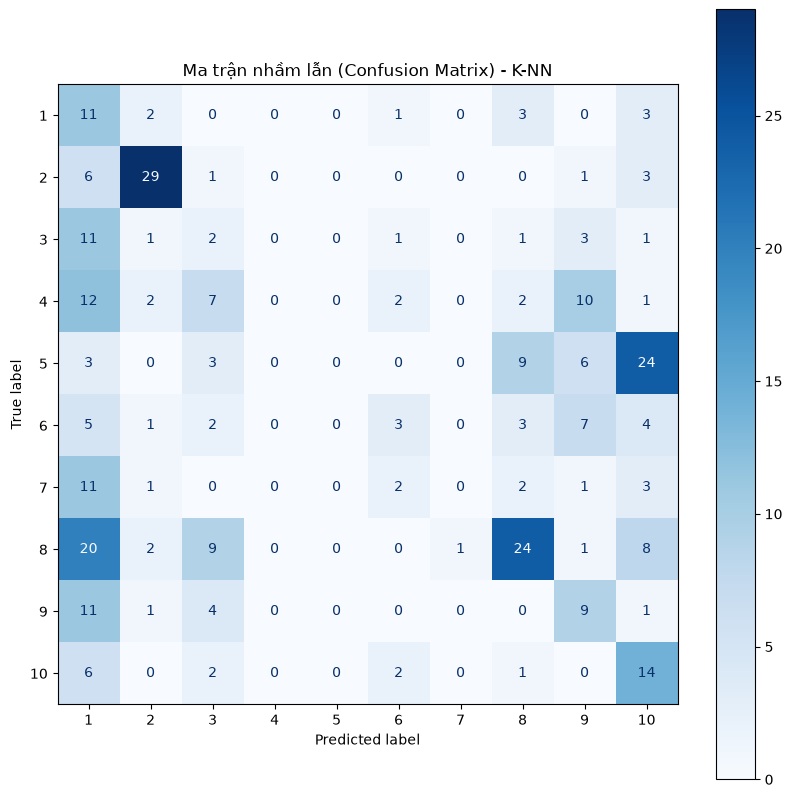

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support
import matplotlib.pyplot as plt

print("=== ĐÁNH GIÁ CHI TIẾT MÔ HÌNH K-NN ===")
# Tính toán Precision, Recall, F1-score
p_knn, r_knn, f1_knn, _ = precision_recall_fscore_support(y_test, y_pred_knn, average='macro')
print(f"Precision (Macro): {p_knn:.4f}")
print(f"Recall (Macro):    {r_knn:.4f}")
print(f"F1-Score (Macro):  {f1_knn:.4f}\n")

print("Báo cáo chi tiết từng lớp (Classification Report):")
print(classification_report(y_test, y_pred_knn, labels=selected_classes))

# Vẽ Confusion Matrix cho K-NN
cm_knn = confusion_matrix(y_test, y_pred_knn, labels=selected_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=selected_classes)
fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title("Ma trận nhầm lẫn (Confusion Matrix) - K-NN")
plt.show()

In [25]:
# --- THỬ NGHIỆM VỚI BASELINE (PIXEL THÔ) VÀ K-NN KHÁC K ---
print("--- SO SÁNH CÁC PHƯƠNG PHÁP ---")

# 1. Trích xuất đặc trưng Pixel thô cho tập Train/Test
print("Đang trích xuất đặc trưng Pixel thô (Baseline)...")
X_train_pixel, y_train_pixel = [], []
for img_id in train_subset_ids:
    img = load_and_crop_image(img_id)
    feat = extract_features(img, method='pixel') # Chuyển sang pixel
    X_train_pixel.append(feat)
    y_train_pixel.append(labels[img_id-1])

X_test_pixel, y_test_pixel = [], []
for img_id in test_subset_ids:
    img = load_and_crop_image(img_id)
    feat = extract_features(img, method='pixel')
    X_test_pixel.append(feat)
    y_test_pixel.append(labels[img_id-1])

X_train_pixel = np.array(X_train_pixel)
X_test_pixel = np.array(X_test_pixel)

# 2. Huấn luyện K-NN với Baseline
knn_pixel = KNeighborsClassifier(n_neighbors=5)
knn_pixel.fit(X_train_pixel, y_train_pixel)
y_pred_pixel = knn_pixel.predict(X_test_pixel)
print(f"-> Accuracy K-NN (Baseline Pixel): {accuracy_score(y_test_pixel, y_pred_pixel):.4f}")

# 3. Thử K-NN với K khác (K=3) trên đặc trưng HOG
knn_k3 = KNeighborsClassifier(n_neighbors=3)
knn_k3.fit(X_train_hog, y_train)
y_pred_k3 = knn_k3.predict(X_test_hog)
print(f"-> Accuracy K-NN (HOG, k=3): {accuracy_score(y_test, y_pred_k3):.4f}")

--- SO SÁNH CÁC PHƯƠNG PHÁP ---
Đang trích xuất đặc trưng Pixel thô (Baseline)...
[Cảnh báo] Không tìm thấy mask cho ảnh 3294 tại đường dẫn: 102segmentations\segmim\image_03294_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3302 tại đường dẫn: 102segmentations\segmim\image_03302_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3313 tại đường dẫn: 102segmentations\segmim\image_03313_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3315 tại đường dẫn: 102segmentations\segmim\image_03315_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3333 tại đường dẫn: 102segmentations\segmim\image_03333_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3336 tại đường dẫn: 102segmentations\segmim\image_03336_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3345 tại đường dẫn: 102segmentations\segmim\image_03345_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3356 tại đường dẫn: 102segmentations\segmim\image_03356_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3360 tại đường dẫn: 102segmentations\se

In [26]:
from sklearn.decomposition import PCA
import time

print("=== THỬ NGHIỆM GIẢM CHIỀU VỚI PCA (ĐẶC TRƯNG HOG) ===")

# 1. Khởi tạo PCA để giảm từ 8100 chiều xuống 100 chiều
pca = PCA(n_components=100, random_state=42)

# 2. Học PCA trên tập Train và biến đổi dữ liệu
start_time = time.time()
X_train_pca = pca.fit_transform(X_train_hog)
X_test_pca = pca.transform(X_test_hog)
print(f"Thời gian chạy PCA: {time.time() - start_time:.2f} giây")

# 3. Huấn luyện lại K-NN trên dữ liệu đã giảm chiều
knn_pca = KNeighborsClassifier(n_neighbors=5)
start_time = time.time()
knn_pca.fit(X_train_pca, y_train)
y_pred_pca = knn_pca.predict(X_test_pca)
end_time = time.time()

print(f"Thời gian huấn luyện K-NN (sau PCA): {end_time - start_time:.2f} giây")
print(f"Độ chính xác (Accuracy) sau khi dùng PCA: {accuracy_score(y_test, y_pred_pca):.4f}")

# So sánh với lúc chưa dùng PCA
print("\n--- SO SÁNH ---")
print(f"Accuracy K-NN (HOG gốc 8100 chiều): 0.2857 (lấy từ Ô 4)")
print(f"Accuracy K-NN (HOG + PCA 100 chiều): {accuracy_score(y_test, y_pred_pca):.4f}")

=== THỬ NGHIỆM GIẢM CHIỀU VỚI PCA (ĐẶC TRƯNG HOG) ===
Thời gian chạy PCA: 0.11 giây
Thời gian huấn luyện K-NN (sau PCA): 0.01 giây
Độ chính xác (Accuracy) sau khi dùng PCA: 0.2857

--- SO SÁNH ---
Accuracy K-NN (HOG gốc 8100 chiều): 0.2857 (lấy từ Ô 4)
Accuracy K-NN (HOG + PCA 100 chiều): 0.2857


[Cảnh báo] Không tìm thấy mask cho ảnh 6734 tại đường dẫn: 102segmentations\segmim\image_06734_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 5087 tại đường dẫn: 102segmentations\segmim\image_05087_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 6612 tại đường dẫn: 102segmentations\segmim\image_06612_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 5629 tại đường dẫn: 102segmentations\segmim\image_05629_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 5147 tại đường dẫn: 102segmentations\segmim\image_05147_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 7162 tại đường dẫn: 102segmentations\segmim\image_07162_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 7200 tại đường dẫn: 102segmentations\segmim\image_07200_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 3284 tại đường dẫn: 102segmentations\segmim\image_03284_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 6395 tại đường dẫn: 102segmentations\segmim\image_06395_segim.png
[Cảnh báo] Không tìm thấy mask cho ảnh 7086 tại đường d

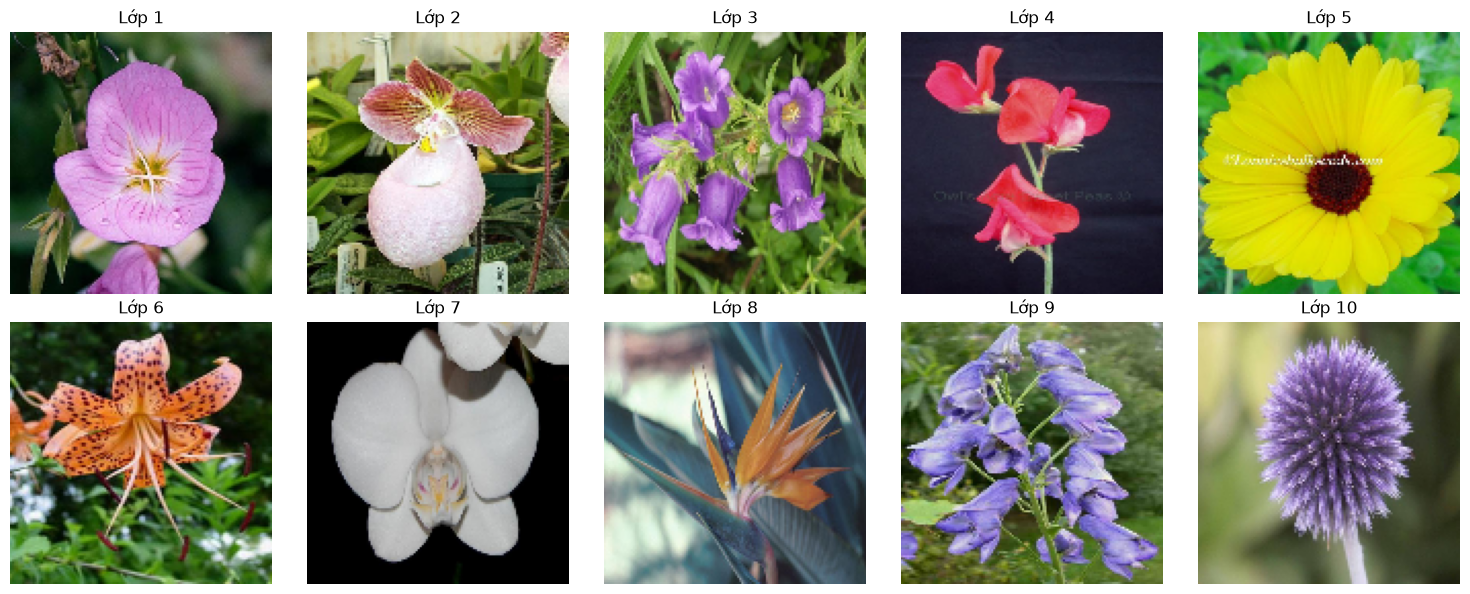

In [34]:
# Trực quan hóa ảnh mẫu của 10 lớp đầu tiên
plt.figure(figsize=(15, 6))
for i, class_id in enumerate(np.arange(1, 11)):
    # Tìm ID của ảnh đầu tiên thuộc lớp này
    img_id = np.where(labels == class_id)[0][0] + 1
    img = load_and_crop_image(img_id)
    
    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(f"Lớp {class_id}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [28]:
print("=== THỬ NGHIỆM CÁC THAM SỐ CỦA MÔ HÌNH ===\n")

# 1. K-NN với metric khác (Manhattan thay vì Euclidean)
knn_manhattan = KNeighborsClassifier(n_neighbors=5, metric='manhattan')
knn_manhattan.fit(X_train_hog, y_train)
acc_manhattan = accuracy_score(y_test, knn_manhattan.predict(X_test_hog))
print(f"-> K-NN (k=5, metric='manhattan'): Accuracy = {acc_manhattan:.4f}")

# 2. Cây quyết định với criterion khác (Entropy thay vì Gini)
dt_entropy = DecisionTreeClassifier(max_depth=15, criterion='entropy', random_state=42)
dt_entropy.fit(X_train_hog, y_train)
acc_entropy = accuracy_score(y_test, dt_entropy.predict(X_test_hog))
print(f"-> Decision Tree (max_depth=15, criterion='entropy'): Accuracy = {acc_entropy:.4f}")

# 3. Thử max_depth khác cho Cây quyết định (max_depth=5)
dt_depth_5 = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_depth_5.fit(X_train_hog, y_train)
acc_depth_5 = accuracy_score(y_test, dt_depth_5.predict(X_test_hog))
print(f"-> Decision Tree (max_depth=5): Accuracy = {acc_depth_5:.4f}")

print("\n--- HOÀN TẤT TOÀN BỘ BÀI TẬP ---")

=== THỬ NGHIỆM CÁC THAM SỐ CỦA MÔ HÌNH ===

-> K-NN (k=5, metric='manhattan'): Accuracy = 0.3137
-> Decision Tree (max_depth=15, criterion='entropy'): Accuracy = 0.2050
-> Decision Tree (max_depth=5): Accuracy = 0.1491

--- HOÀN TẤT TOÀN BỘ BÀI TẬP ---


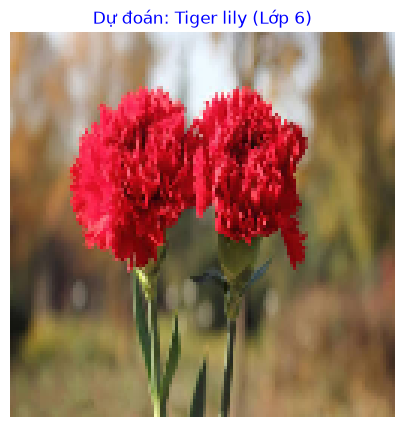

MÔ HÌNH DỰ ĐOÁN: TIGER LILY


In [36]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. DANH SÁCH 102 LOÀI HOA (Dùng để dịch số thành tên)
flower_names = [
    "pink primrose", "hard-leaved pocket orchid", "canterbury bells", "sweet pea", "english marigold", 
    "tiger lily", "moon orchid", "bird of paradise", "monkshood", "globe thistle", 
    "snapdragon", "colt's foot", "king protea", "spear thistle", "yellow iris", 
    "globe-flower", "purple coneflower", "peruvian lily", "balloon flower", "giant white arum lily", 
    "fire lily", "pincushion flower", "fritillary", "red ginger", "grape hyacinth", 
    "corn poppy", "prince of wales feathers", "stemless gentian", "artichoke", "sweet william", 
    "carnation", "garden phlox", "love in the mist", "mexican aster", "alpine sea holly", 
    "ruby-lipped cattleya", "cape flower", "great masterwort", "siam tulip", "lenten rose", 
    "barbeton daisy", "daffodil", "sword lily", "poinsettia", "bolero deep blue", 
    "wallflower", "marigold", "buttercup", "oxeye daisy", "common dandelion", 
    "petunia", "wild pansy", "primula", "sunflower", "pelargonium", 
    "bishop of llandaff", "gaura", "geranium", "orange dahlia", "pink-yellow dahlia", 
    "cautleya spicata", "japanese anemone", "black-eyed susan", "silverbush", "californian poppy", 
    "osteospermum", "spring crocus", "bearded iris", "windflower", "tree poppy", 
    "gazania", "azalea", "water lily", "rose", "thorn apple", 
    "morning glory", "passion flower", "lotus", "toad lily", "anthurium", 
    "frangipani", "clematis", "hibiscus", "columbine", "desert-rose", 
    "tree mallow", "magnolia", "cyclamen", "watercress", "canna lily", 
    "hippeastrum", "bee balm", "ball moss", "foxglove", "bougainvillea", 
    "camellia", "mallow", "mexican petunia", "bromelia", "blanket flower", 
    "trumpet creeper", "blackberry lily"
]

# 2. ĐƯỜNG DẪN ẢNH CẦN DỰ ĐOÁN
# Bạn hãy đổi tên file này thành tên ảnh bạn đã tải về máy nhé
img_path = 'images.jpg' 

# 3. HÀM XỬ LÝ ẢNH MỚI
def process_new_image(path):
    img = Image.open(path).convert('RGB')
    img_np = np.array(img)
    
    # Tự động cắt nền (dựa trên màu sáng/trắng)
    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    _, thresh = cv2.threshold(gray, 240, 255, cv2.THRESH_BINARY_INV)
    coords = cv2.findNonZero(thresh)
    if coords is not None:
        x, y, w, h = cv2.boundingRect(coords)
        img_cropped = img_np[y:y+h, x:x+w]
    else:
        img_cropped = img_np
        
    # Resize về 128x128 giống lúc huấn luyện
    img_resized = cv2.resize(img_cropped, (128, 128))
    return img_resized

# 4. CHẠY DỰ ĐOÁN
try:
    new_img = process_new_image(img_path)
    
    # Trích xuất đặc trưng Pixel thô (Baseline - giống Ô 6)
    new_feat = new_img.flatten() / 255.0
    new_feat = new_feat.reshape(1, -1)
    
    # Dự đoán bằng mô hình K-NN Pixel đã huấn luyện
    # (Lưu ý: Biến knn_pixel phải được tạo ra từ Ô 6)
    prediction_num = knn_pixel.predict(new_feat)[0]
    
    # Lấy tên hoa tương ứng (Trừ 1 vì mảng bắt đầu từ 0)
    prediction_name = flower_names[prediction_num - 1]
    
    # Hiển thị kết quả
    plt.figure(figsize=(5, 5))
    plt.imshow(new_img)
    plt.title(f"Dự đoán: {prediction_name.capitalize()} (Lớp {prediction_num})", fontsize=12, color='blue')
    plt.axis('off')
    plt.show()
    
    print("="*40)
    print(f"MÔ HÌNH DỰ ĐOÁN: {prediction_name.upper()}")
    print("="*40)
    
except Exception as e:
    print(f"Lỗi: {e}")
    print("Hãy kiểm tra lại:")
    print("1. File ảnh đã nằm cùng thư mục với code chưa?")
    print("2. Bạn đã chạy Ô 6 (để tạo mô hình knn_pixel) chưa?")